In [47]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import csv
import re
from datetime import datetime
import os


try:
    from google.colab import files
    uploaded = files.upload()
    file_path = list(uploaded.keys())[0]

except ImportError:

    file_path = 'manali.csv'

print("Dataset file:", file_path)


Saving manali.csv to manali (6).csv
Dataset file: manali (6).csv


In [48]:


import csv
import re
from datetime import datetime

records = []
current_month = None

with open(file_path, 'r', encoding='utf-8-sig') as file:
    reader = csv.reader(file)

    for row in reader:
        if not row:
            continue

        first = row[0].strip().strip('"')

        #  monthly headings
        if re.fullmatch(r'[A-Za-z]+-\d{4}', first):
            current_month = datetime.strptime(first, '%B-%Y')
            continue

        # Skip year headings
        if first.lower() == 'year':
            continue

        # Process daily records
        if current_month and first.isdigit():
            day = int(first)

            try:
                date = datetime(
                    current_month.year,
                    current_month.month,
                    day
                )
            except ValueError:
                continue

            for hour in range(24):
                raw_value = row[hour + 1].strip() if hour + 1 < len(row) else ''

                value = float(raw_value) if raw_value else None

                records.append({
                    'Date': date,
                    'Hour': hour,
                    'AQI': value
                })

# Convert records into a DataFrame
df = pd.DataFrame(records)

df['Date'] = pd.to_datetime(df['Date'])

print(df.head())
print(df.shape)
print(df.info())


        Date  Hour  AQI
0 2017-07-01     0  NaN
1 2017-07-01     1  NaN
2 2017-07-01     2  NaN
3 2017-07-01     3  NaN
4 2017-07-01     4  NaN
(55584, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55584 entries, 0 to 55583
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    55584 non-null  datetime64[ns]
 1   Hour    55584 non-null  int64         
 2   AQI     48684 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 1.3 MB
None


In [49]:

print("Dataset dimensions:", df.shape)


print("\nData types:")
print(df.dtypes)


print("\nColumn names:")
print(df.columns)

Dataset dimensions: (55584, 3)

Data types:
Date    datetime64[ns]
Hour             int64
AQI            float64
dtype: object

Column names:
Index(['Date', 'Hour', 'AQI'], dtype='object')


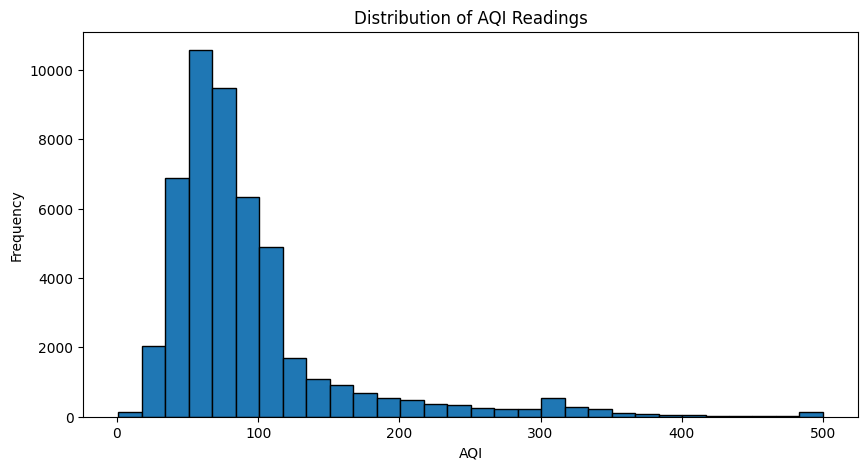

In [50]:

# Plot histogram of AQI readings

plt.figure(figsize=(10, 5))

plt.hist(df['AQI'].dropna(), bins=30, edgecolor='black')

plt.title('Distribution of AQI Readings')
plt.xlabel('AQI')
plt.ylabel('Frequency')

plt.show()


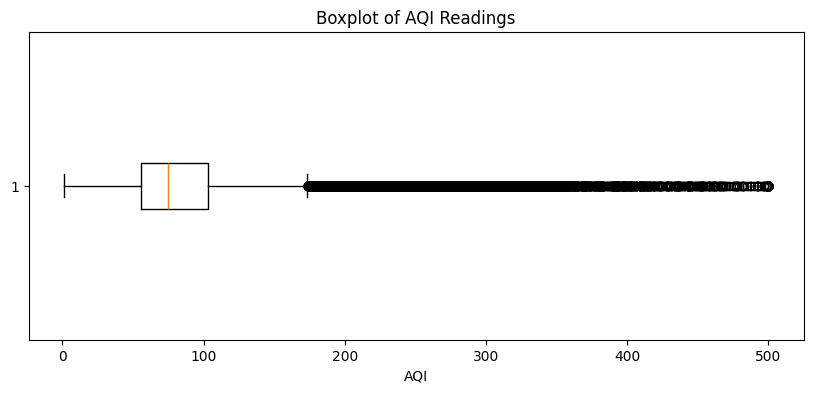

In [51]:

# Plot boxplot of AQI readings

plt.figure(figsize=(10, 4))

plt.boxplot(df['AQI'].dropna(), vert=False)

plt.title('Boxplot of AQI Readings')
plt.xlabel('AQI')

plt.show()


In [52]:

Q1 = df['AQI'].quantile(0.25)
Q3 = df['AQI'].quantile(0.75)


IQR = Q3 - Q1


lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR


outliers = df[
    (df['AQI'] < lower_limit) |
    (df['AQI'] > upper_limit)
]


print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print("Number of outliers:", len(outliers))
print("Percentage of outliers:",
      (len(outliers) / df['AQI'].notna().sum()) * 100)

Q1: 56.0
Q3: 103.0
IQR: 47.0
Lower limit: -14.5
Upper limit: 173.5
Number of outliers: 4409
Percentage of outliers: 9.056363486977242


In [53]:
# Calculate missing AQI readings for each year
missing_by_year = df.groupby(
    df['Date'].dt.year
)['AQI'].apply(lambda x: x.isnull().sum())

# Calculate total readings for each year
total_by_year = df.groupby(
    df['Date'].dt.year
)['AQI'].count() + missing_by_year

# Calculate percentage of missing readings
missing_percentage = (missing_by_year / total_by_year) * 100


missing_summary = pd.DataFrame({
    'Total Readings': total_by_year,
    'Missing Readings': missing_by_year,
    'Missing Percentage': missing_percentage
})

print(missing_summary)

      Total Readings  Missing Readings  Missing Percentage
Date                                                      
2017            3000              1662           55.400000
2018            8760               371            4.235160
2019            8760              2334           26.643836
2020            8784               304            3.460838
2021            8760               835            9.531963
2022            8760               457            5.216895
2023            8760               937           10.696347


In [54]:
# a separate dataset without missing AQI values

clean_df = df.dropna(subset=['AQI']).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)
print("Missing AQI values after cleaning:", clean_df['AQI'].isnull().sum())

Original dataset shape: (55584, 3)
Cleaned dataset shape: (48684, 3)
Missing AQI values after cleaning: 0


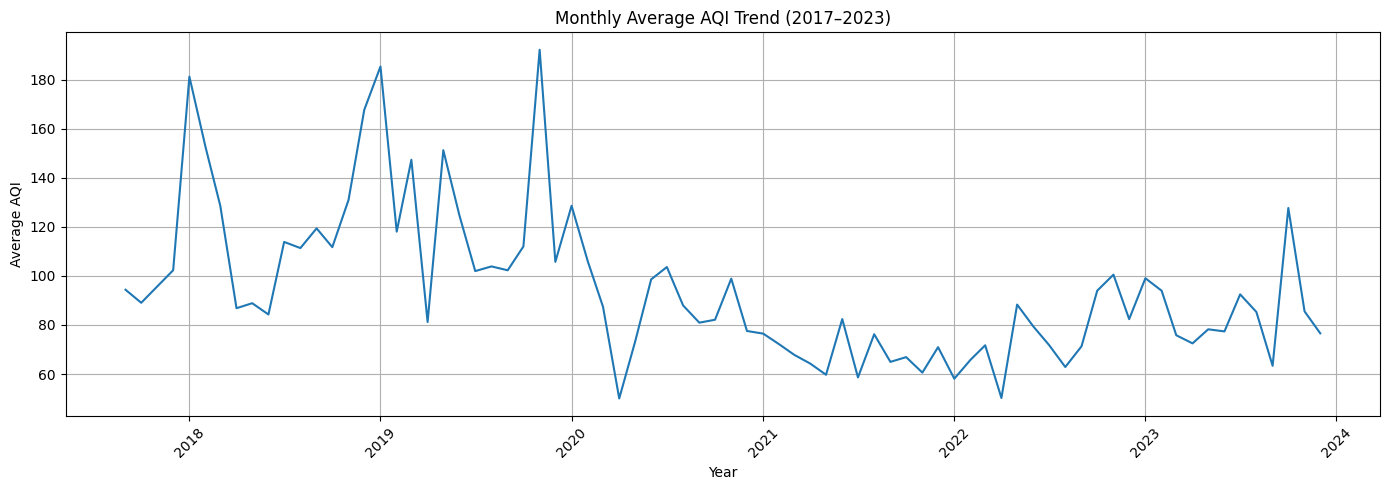

In [55]:
#  monthly average AQI
monthly_aqi = clean_df.groupby(
    clean_df['Date'].dt.to_period('M')
)['AQI'].mean()

# Convert month periods into timestamps
monthly_aqi.index = monthly_aqi.index.to_timestamp()

# Plot the monthly AQI trend
plt.figure(figsize=(14, 5))
plt.plot(monthly_aqi.index, monthly_aqi.values)

plt.title('Monthly Average AQI Trend (2017–2023)')
plt.xlabel('Year')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

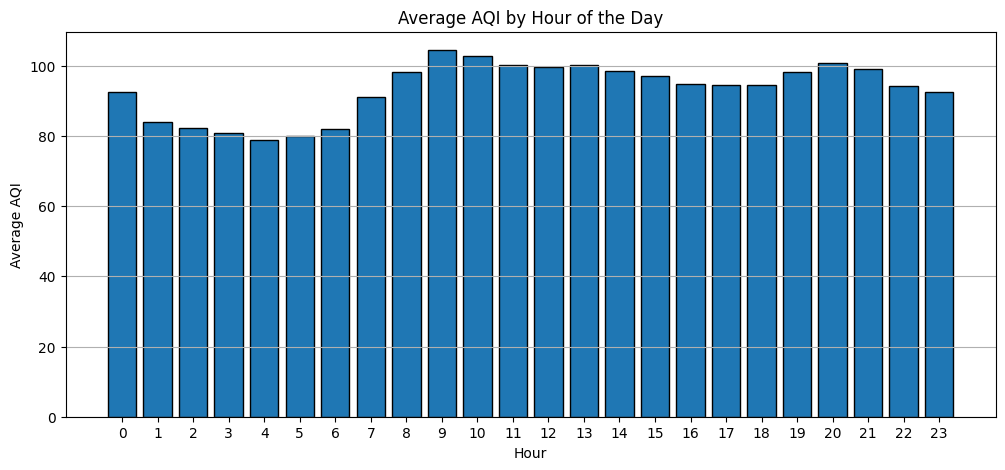

In [56]:
# average AQI for each hour
hourly_aqi = clean_df.groupby('Hour')['AQI'].mean()

# Plot average AQI by hour
plt.figure(figsize=(12, 5))
plt.bar(hourly_aqi.index, hourly_aqi.values, edgecolor='black')

plt.title('Average AQI by Hour of the Day')
plt.xlabel('Hour')
plt.ylabel('Average AQI')
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()

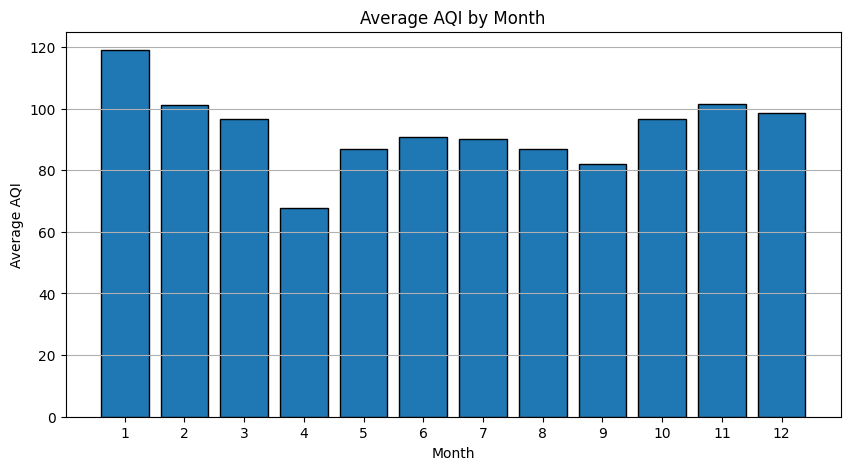

In [57]:
# average AQI for each month
monthly_avg = clean_df.groupby(
    clean_df['Date'].dt.month
)['AQI'].mean()

# Plot average AQI by month
plt.figure(figsize=(10, 5))
plt.bar(monthly_avg.index, monthly_avg.values, edgecolor='black')

plt.title('Average AQI by Month')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.xticks(range(1, 13))
plt.grid(axis='y')
plt.show()

In [58]:

# Define chronological train-test split date

dates = sorted(df['Date'].unique())

cutoff_index = int(len(dates) * 0.8)
cutoff_date = dates[cutoff_index]

print("Training data ends before:", cutoff_date)
print("Testing data starts from:", cutoff_date)

Training data ends before: 2022-09-24 00:00:00
Testing data starts from: 2022-09-24 00:00:00


In [59]:
# a copy of the original dataset
v2_df = df.copy()

# Combine Date and Hour into a single DateTime column
v2_df['DateTime'] = (
    v2_df['Date'] +
    pd.to_timedelta(v2_df['Hour'], unit='h')
)

# Sort the data chronologically
v2_df = v2_df.sort_values('DateTime').reset_index(drop=True)

# Create lag features using previous AQI readings
v2_df['AQI_Lag_1'] = v2_df['AQI'].shift(1)
v2_df['AQI_Lag_24'] = v2_df['AQI'].shift(24)

#  the average AQI of the previous 24 hours
v2_df['AQI_Rolling_24'] = (
    v2_df['AQI']
    .rolling(window=24, min_periods=1)
    .mean()
    .shift(1)
)

# Extract date-related features
v2_df['Year'] = v2_df['DateTime'].dt.year
v2_df['Month'] = v2_df['DateTime'].dt.month
v2_df['Day'] = v2_df['DateTime'].dt.day
v2_df['DayOfWeek'] = v2_df['DateTime'].dt.dayofweek

# Remove rows where the target or required lag features are missing
v2_df = v2_df.dropna(
    subset=['AQI', 'AQI_Lag_1', 'AQI_Lag_24', 'AQI_Rolling_24']
).copy()

# Select input features
features_v2 = [
    'Hour', 'Month', 'Year', 'Day', 'DayOfWeek',
    'AQI_Lag_1', 'AQI_Lag_24', 'AQI_Rolling_24'
]


train_v2 = v2_df[v2_df['Date'] < cutoff_date].copy()
test_v2 = v2_df[v2_df['Date'] >= cutoff_date].copy()

X_train_v2 = train_v2[features_v2]
X_test_v2 = test_v2[features_v2]

y_train_v2 = train_v2['AQI']
y_test_v2 = test_v2['AQI']


print("Version 2 dataset shape:", v2_df.shape)
print("Training data shape:", X_train_v2.shape)
print("Testing data shape:", X_test_v2.shape)

print("Training date range:",
      train_v2['Date'].min(), "to", train_v2['Date'].max())

print("Testing date range:",
      test_v2['Date'].min(), "to", test_v2['Date'].max())

print("\nMissing values in Version 2 features:")
print(v2_df[features_v2].isnull().sum())

Version 2 dataset shape: (45376, 11)
Training data shape: (35831, 8)
Testing data shape: (9545, 8)
Training date range: 2017-09-28 00:00:00 to 2022-09-23 00:00:00
Testing date range: 2022-09-24 00:00:00 to 2023-12-31 00:00:00

Missing values in Version 2 features:
Hour              0
Month             0
Year              0
Day               0
DayOfWeek         0
AQI_Lag_1         0
AQI_Lag_24        0
AQI_Rolling_24    0
dtype: int64


In [60]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#  Baseline Model


baseline_v2 = DummyRegressor(strategy='mean')
baseline_v2.fit(X_train_v2, y_train_v2)

baseline_pred_v2 = baseline_v2.predict(X_test_v2)



#  Multiple Linear Regression


lr_v2 = LinearRegression()
lr_v2.fit(X_train_v2, y_train_v2)

lr_pred_v2 = lr_v2.predict(X_test_v2)



#  Random Forest Regression


rf_v2 = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_v2.fit(X_train_v2, y_train_v2)

rf_pred_v2 = rf_v2.predict(X_test_v2)






models = {
    'Baseline': baseline_pred_v2,
    'Multiple Linear Regression': lr_pred_v2,
    'Random Forest': rf_pred_v2
}

for name, predictions in models.items():

    mae = mean_absolute_error(y_test_v2, predictions)
    mse = mean_squared_error(y_test_v2, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_v2, predictions)

    print("\n", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


 Baseline
MAE: 30.09983046979214
MSE: 2103.119907983975
RMSE: 45.8597853024191
R2 Score: -0.028530170160559365

 Multiple Linear Regression
MAE: 16.612185043997012
MSE: 953.3438973520441
RMSE: 30.876267542435308
R2 Score: 0.5337674484261978

 Random Forest
MAE: 18.314844421162913
MSE: 1100.1535201781037
RMSE: 33.16856222657388
R2 Score: 0.46197024572117484


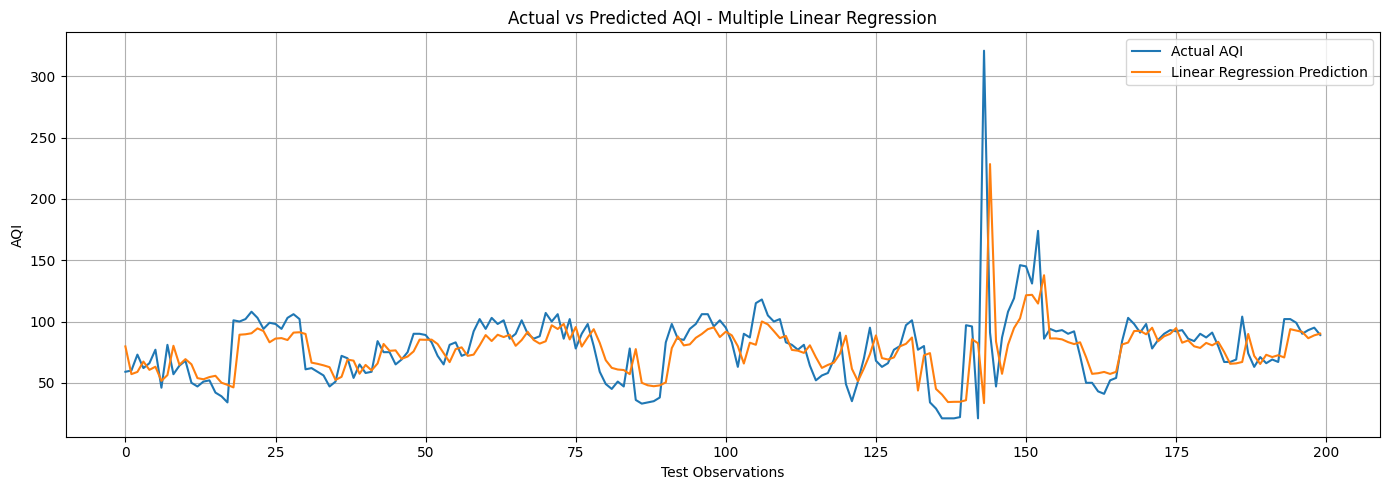

In [61]:
# Plot Actual vs Linear Regression Predictions
plt.figure(figsize=(14, 5))

plt.plot(
    y_test_v2.values[:200],
    label='Actual AQI'
)

plt.plot(
    lr_pred_v2[:200],
    label='Linear Regression Prediction'
)

plt.title('Actual vs Predicted AQI - Multiple Linear Regression')
plt.xlabel('Test Observations')
plt.ylabel('AQI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

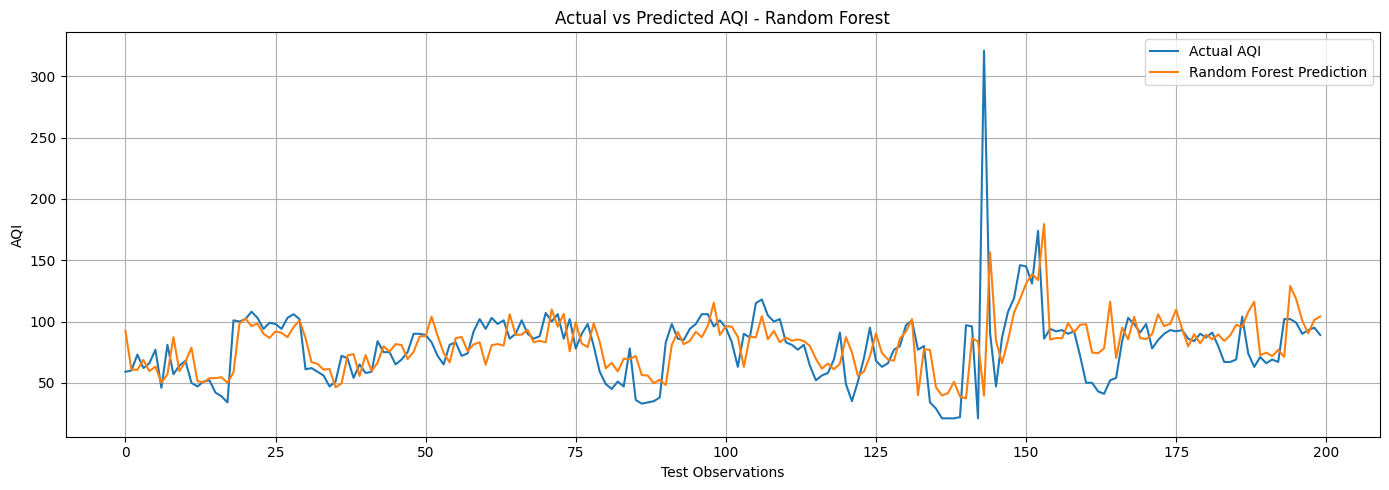

In [62]:
# Plot Actual vs Random Forest Predictions
plt.figure(figsize=(14, 5))

plt.plot(
    y_test_v2.values[:200],
    label='Actual AQI'
)

plt.plot(
    rf_pred_v2[:200],
    label='Random Forest Prediction'
)

plt.title('Actual vs Predicted AQI - Random Forest')
plt.xlabel('Test Observations')
plt.ylabel('AQI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [63]:

from sklearn.model_selection import TimeSeriesSplit

# Create 5 chronological splits
tscv = TimeSeriesSplit(n_splits=5)

# Store the validation scores
cv_scores = []

# Perform cross-validation using Multiple Linear Regression
for fold, (train_index, val_index) in enumerate(
    tscv.split(X_train_v2), start=1
):

    # Divide training data into training and validation sets
    X_fold_train = X_train_v2.iloc[train_index]
    X_fold_val = X_train_v2.iloc[val_index]

    y_fold_train = y_train_v2.iloc[train_index]
    y_fold_val = y_train_v2.iloc[val_index]

    # Train the model
    model = LinearRegression()
    model.fit(X_fold_train, y_fold_train)

    # Make predictions
    predictions = model.predict(X_fold_val)

    #  MAE
    mae = mean_absolute_error(y_fold_val, predictions)

    cv_scores.append(mae)

    print("Fold", fold, "MAE:", mae)


print("\nAverage Cross-Validation MAE:", np.mean(cv_scores))

Fold 1 MAE: 38.14686477302298
Fold 2 MAE: 25.867661702781735
Fold 3 MAE: 14.215500618107077
Fold 4 MAE: 10.849646512471496
Fold 5 MAE: 11.893506300024674

Average Cross-Validation MAE: 20.19463598128159


In [64]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20]
}

tscv = TimeSeriesSplit(n_splits=3)

rf = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_train_v2, y_train_v2)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation MAE:", -grid_search.best_score_)

Best Parameters: {'max_depth': 10, 'n_estimators': 100}
Best Cross-Validation MAE: 21.392205093373136


In [65]:
# Get the best Random Forest model
best_rf = grid_search.best_estimator_

# Predict on the unseen test data
best_rf_pred = best_rf.predict(X_test_v2)

# Calculate evaluation metrics
best_rf_mae = mean_absolute_error(y_test_v2, best_rf_pred)
best_rf_mse = mean_squared_error(y_test_v2, best_rf_pred)
best_rf_rmse = np.sqrt(best_rf_mse)
best_rf_r2 = r2_score(y_test_v2, best_rf_pred)

print("Tuned Random Forest Performance")
print("MAE:", best_rf_mae)
print("MSE:", best_rf_mse)
print("RMSE:", best_rf_rmse)
print("R2 Score:", best_rf_r2)

Tuned Random Forest Performance
MAE: 16.914514988240338
MSE: 1035.2609338634416
RMSE: 32.17547099676152
R2 Score: 0.49370594590213046


In [66]:
# Create an error analysis DataFrame
error_df = pd.DataFrame({
    'Actual AQI': y_test_v2.values,
    'Predicted AQI': lr_pred_v2
})

# Calculate prediction errors
error_df['Error'] = (
    error_df['Actual AQI'] - error_df['Predicted AQI']
)

error_df['Absolute Error'] = error_df['Error'].abs()

# Display error statistics
print("Error Analysis")
print("Mean Error:", error_df['Error'].mean())
print("Mean Absolute Error:", error_df['Absolute Error'].mean())
print("Median Absolute Error:", error_df['Absolute Error'].median())
print("Maximum Absolute Error:", error_df['Absolute Error'].max())

print("\nPredictions within 10 AQI points:",
      (error_df['Absolute Error'] <= 10).mean() * 100, "%")

print("Predictions within 20 AQI points:",
      (error_df['Absolute Error'] <= 20).mean() * 100, "%")

Error Analysis
Mean Error: 3.6166795123456246
Mean Absolute Error: 16.612185043997012
Median Absolute Error: 9.484985159403095
Maximum Absolute Error: 433.10391894491477

Predictions within 10 AQI points: 51.964379256155055 %
Predictions within 20 AQI points: 77.78941854374017 %
